<a href="https://colab.research.google.com/github/pranjalgahlot123/nimbus-cloud-optimizer/blob/main/NIMBUS_DORA_Engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

NIMBUS_DORA_Engine.ipynb
01 — Environment Setup

02 — Cloud Infrastructure Models

03 — Workload Generation

04 — Cloud Simulation Engine

05 — FCFS Scheduling

06 — Best Fit Scheduling

07 — DORA Optimization Algorithm

08 — Energy Consumption Model

09 — Server Consolidation

10 — Performance Benchmarking

11 — Visualization and Results

12 — API Output for Frontend

In [ ]:
!pip install -q numpy pandas matplotlib fastapi pydantic

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import random
import copy
import json
import time

from dataclasses import dataclass, field

random.seed(42)
np.random.seed(42)

print("NIMBUS DORA Engine initialized successfully!")

NIMBUS DORA Engine initialized successfully!


In [ ]:
# NIMBUS CLOUD CONFIGURATION

TOTAL_SERVERS = 20
TOTAL_WORKLOADS = 100

CPU_PER_SERVER = 16
RAM_PER_SERVER = 32

IDLE_POWER = 80
MAX_POWER = 250

PROJECT_NAME = "NIMBUS"
ALGORITHM_NAME = "DORA"

print("Project:", PROJECT_NAME)
print("Servers:", TOTAL_SERVERS)
print("Workloads:", TOTAL_WORKLOADS)

Project: NIMBUS
Servers: 20
Workloads: 100


02 — Cloud Infrastructure Models

In [ ]:

from dataclasses import dataclass, field

@dataclass
class Server:

    server_id: str
    cpu_capacity: int = 16
    ram_capacity: int = 32

    idle_power: float = 80
    max_power: float = 250

    cpu_used: int = 0
    ram_used: int = 0

    active: bool = True
    workloads: list = field(default_factory=list)

    @property
    def cpu_utilization(self):
        return self.cpu_used / self.cpu_capacity

    @property
    def ram_utilization(self):
        return self.ram_used / self.ram_capacity

    def can_allocate(self, workload):

        return (
            self.active
            and self.cpu_used + workload.cpu_required <= self.cpu_capacity
            and self.ram_used + workload.ram_required <= self.ram_capacity
        )

    def allocate(self, workload):

        if not self.can_allocate(workload):
            return False

        self.cpu_used += workload.cpu_required
        self.ram_used += workload.ram_required
        self.workloads.append(workload)

        return True


# Create 20 virtual servers
servers = [
    Server(server_id=f"S{i:02d}")
    for i in range(1, TOTAL_SERVERS + 1)
]

print("Total servers created:", len(servers))
print("First server:", servers[0])


Total servers created: 20
First server: Server(server_id='S01', cpu_capacity=16, ram_capacity=32, idle_power=80, max_power=250, cpu_used=0, ram_used=0, active=True, workloads=[])


In [ ]:
server_data = pd.DataFrame([
    {
        "Server ID": s.server_id,
        "CPU Capacity": s.cpu_capacity,
        "RAM Capacity (GB)": s.ram_capacity,
        "Idle Power (W)": s.idle_power,
        "Max Power (W)": s.max_power,
        "Status": "Active"
    }
    for s in servers
])

display(server_data)

,Server ID,CPU Capacity,RAM Capacity (GB),Idle Power (W),Max Power (W),Status
0,S01,16,32,80,250,Active
1,S02,16,32,80,250,Active
2,S03,16,32,80,250,Active
3,S04,16,32,80,250,Active
4,S05,16,32,80,250,Active
5,S06,16,32,80,250,Active
6,S07,16,32,80,250,Active
7,S08,16,32,80,250,Active
8,S09,16,32,80,250,Active
9,S10,16,32,80,250,Active


03 — Workload Generation

In [ ]:

from dataclasses import dataclass
import random

@dataclass
class Workload:
    workload_id: str
    cpu_required: int
    ram_required: int
    execution_time: float
    deadline: float
    priority: int


def generate_workloads(number=100, seed=42):

    random.seed(seed)

    workloads = []

    for i in range(1, number + 1):

        cpu = random.choice([1, 2, 4, 8, 12])
        ram = random.choice([2, 4, 8, 16, 24])

        duration = random.randint(5, 60)

        workload = Workload(
            workload_id=f"W{i:03d}",
            cpu_required=cpu,
            ram_required=ram,
            execution_time=duration,
            deadline=random.randint(10, 90),
            priority=random.randint(1, 3)
        )

        workloads.append(workload)

    return workloads


workloads = generate_workloads(TOTAL_WORKLOADS)

print("Total workloads generated:", len(workloads))
print("First workload:", workloads[0])


Total workloads generated: 100
First workload: Workload(workload_id='W001', cpu_required=1, ram_required=2, execution_time=52, deadline=45, priority=1)


In [ ]:
workload_data = pd.DataFrame([
    {
        "Workload ID": w.workload_id,
        "CPU Required": w.cpu_required,
        "RAM Required (GB)": w.ram_required,
        "Execution Time (min)": w.execution_time,
        "Deadline (min)": w.deadline,
        "Priority": w.priority
    }
    for w in workloads
])

display(workload_data.head(15))

,Workload ID,CPU Required,RAM Required (GB),Execution Time (min),Deadline (min),Priority
0,W001,1,2,52,45,1
1,W002,2,4,52,23,3
2,W003,12,2,42,64,1
3,W004,1,2,18,39,3
4,W005,12,2,40,35,3
5,W006,12,16,19,67,3
6,W007,4,2,53,30,3
7,W008,8,8,22,29,1
8,W009,4,2,10,58,1
9,W010,4,8,43,43,1


Check workload distribution

In [ ]:
print("Total workloads:", len(workloads))

print("\nPriority distribution:")
print(workload_data["Priority"].value_counts().sort_index())

print("\nCPU requirement distribution:")
print(workload_data["CPU Required"].value_counts().sort_index())

Total workloads: 100

Priority distribution:
Priority
1    43
2    28
3    29
Name: count, dtype: int64

CPU requirement distribution:
CPU Required
1     12
2     22
4     23
8     15
12    28
Name: count, dtype: int64


04 — Cloud Simulation Engine

In [ ]:
def create_server_pool():
    """Create a fresh set of servers for each simulation."""
    return [
        Server(
            server_id=f"S{i:02d}",
            cpu_capacity=CPU_PER_SERVER,
            ram_capacity=RAM_PER_SERVER,
            idle_power=IDLE_POWER,
            max_power=MAX_POWER
        )
        for i in range(1, TOTAL_SERVERS + 1)
    ]


def calculate_server_metrics(server):
    """Calculate resource usage for one server."""

    return {
        "Server ID": server.server_id,
        "CPU Used": server.cpu_used,
        "CPU Utilization (%)": round(
            server.cpu_utilization * 100, 2
        ),
        "RAM Used (GB)": server.ram_used,
        "RAM Utilization (%)": round(
            server.ram_utilization * 100, 2
        ),
        "Workloads": len(server.workloads)
    }


def get_infrastructure_metrics(server_pool):
    """Summarize the infrastructure after scheduling."""

    used_servers = [
        server for server in server_pool
        if server.workloads
    ]

    total_cpu_used = sum(
        server.cpu_used for server in used_servers
    )

    total_ram_used = sum(
        server.ram_used for server in used_servers
    )

    return {
        "Total Servers": len(server_pool),
        "Used Servers": len(used_servers),
        "Unused Servers": len(server_pool) - len(used_servers),
        "Total CPU Used": total_cpu_used,
        "Total RAM Used (GB)": total_ram_used
    }


# Create a fresh infrastructure
test_servers = create_server_pool()

print("Simulation engine initialized!")
print("Servers created:", len(test_servers))
print("First server:", test_servers[0].server_id)

Simulation engine initialized!
Servers created: 20
First server: S01


In [ ]:
infrastructure = get_infrastructure_metrics(test_servers)

print("Infrastructure Metrics:")
for metric, value in infrastructure.items():
    print(f"{metric}: {value}")

Infrastructure Metrics:
Total Servers: 20
Used Servers: 0
Unused Servers: 20
Total CPU Used: 0
Total RAM Used (GB): 0


05 — FCFS Scheduling

In [ ]:
def run_fcfs(workload_list):
    # Start with a fresh server pool
    server_pool = create_server_pool()

    allocated = []
    rejected = []

    # Process workloads in arrival order
    for workload in workload_list:

        assigned = False

        # Find the first server with enough resources
        for server in server_pool:

            if server.allocate(workload):

                allocated.append({
                    "Workload ID": workload.workload_id,
                    "Server ID": server.server_id,
                    "CPU Required": workload.cpu_required,
                    "RAM Required": workload.ram_required,
                    "Execution Time": workload.execution_time,
                    "Priority": workload.priority
                })

                assigned = True
                break

        if not assigned:
            rejected.append(workload.workload_id)

    return server_pool, allocated, rejected


# Execute FCFS
fcfs_servers, fcfs_allocations, fcfs_rejected = run_fcfs(workloads)

print("FCFS Scheduling Completed")
print("--------------------------")
print("Total Workloads:", len(workloads))
print("Allocated Workloads:", len(fcfs_allocations))
print("Rejected Workloads:", len(fcfs_rejected))
print("Servers Used:", sum(1 for s in fcfs_servers if s.workloads))

FCFS Scheduling Completed
--------------------------
Total Workloads: 100
Allocated Workloads: 53
Rejected Workloads: 47
Servers Used: 20


In [ ]:
fcfs_results = pd.DataFrame(fcfs_allocations)

display(fcfs_results.head(15))

,Workload ID,Server ID,CPU Required,RAM Required,Execution Time,Priority
0,W001,S01,1,2,52,1
1,W002,S01,2,4,52,3
2,W003,S01,12,2,42,1
3,W004,S01,1,2,18,3
4,W005,S02,12,2,40,3
5,W006,S03,12,16,19,3
6,W007,S02,4,2,53,3
7,W008,S04,8,8,22,1
8,W009,S03,4,2,10,1
9,W010,S04,4,8,43,1


In [ ]:
fcfs_server_metrics = pd.DataFrame([
    calculate_server_metrics(server)
    for server in fcfs_servers
])

display(fcfs_server_metrics)

,Server ID,CPU Used,CPU Utilization (%),RAM Used (GB),RAM Utilization (%),Workloads
0,S01,16,100.00,10,31.25,4
1,S02,16,100.00,4,12.50,2
2,S03,16,100.00,18,56.25,2
3,S04,16,100.00,28,87.50,4
4,S05,16,100.00,32,100.00,2
5,S06,16,100.00,32,100.00,2
6,S07,5,31.25,32,100.00,2
7,S08,16,100.00,10,31.25,3
8,S09,16,100.00,10,31.25,3
9,S10,16,100.00,26,81.25,2


06 — Best Fit Scheduling

In [ ]:
def run_best_fit(workload_list):

    server_pool = create_server_pool()

    allocated = []
    rejected = []

    for workload in workload_list:

        suitable_servers = [
            server for server in server_pool
            if server.can_allocate(workload)
        ]

        if not suitable_servers:
            rejected.append(workload.workload_id)
            continue

        # Select the server with the least remaining
        # normalized CPU and RAM capacity
        best_server = min(
            suitable_servers,
            key=lambda server: (
                (server.cpu_capacity - server.cpu_used - workload.cpu_required)
                / server.cpu_capacity
                +
                (server.ram_capacity - server.ram_used - workload.ram_required)
                / server.ram_capacity
            )
        )

        best_server.allocate(workload)

        allocated.append({
            "Workload ID": workload.workload_id,
            "Server ID": best_server.server_id,
            "CPU Required": workload.cpu_required,
            "RAM Required": workload.ram_required,
            "Execution Time": workload.execution_time,
            "Priority": workload.priority
        })

    return server_pool, allocated, rejected


# Execute Best Fit
best_fit_servers, best_fit_allocations, best_fit_rejected = run_best_fit(workloads)

print("Best Fit Scheduling Completed")
print("------------------------------")
print("Total Workloads:", len(workloads))
print("Allocated Workloads:", len(best_fit_allocations))
print("Rejected Workloads:", len(best_fit_rejected))
print("Servers Used:", sum(1 for s in best_fit_servers if s.workloads))

Best Fit Scheduling Completed
------------------------------
Total Workloads: 100
Allocated Workloads: 54
Rejected Workloads: 46
Servers Used: 20


In [ ]:
def projected_serial_runtime(server, workload):
    """Server busy time if workloads run serially (sum of exec times)."""
    return sum(w.execution_time for w in server.workloads) + workload.execution_time


def calculate_dora_score(server, workload):
    projected_cpu = (server.cpu_used + workload.cpu_required) / server.cpu_capacity
    projected_ram = (server.ram_used + workload.ram_required) / server.ram_capacity

    # 1. Resource fit: reward filling an already-used server (packing)
    resource_fit = (projected_cpu + projected_ram) / 2.0

    # 2. Consolidation: strongly prefer already-active servers
    consolidation = 1.0 if server.workloads else 0.0

    # 3. Resource balance: avoid CPU/RAM skew
    resource_balance = 1.0 - abs(projected_cpu - projected_ram)

    # 4. Energy efficiency: reward high utilization on ACTIVE servers only
    #    (empty servers get penalised so DORA does not spread workloads)
    if server.workloads:
        energy_efficiency = projected_cpu
    else:
        energy_efficiency = 0.0

    score = (
        0.30 * resource_fit
        + 0.30 * consolidation
        + 0.20 * resource_balance
        + 0.20 * energy_efficiency
    )
    return score


def run_dora(workload_list):
    server_pool = create_server_pool()
    allocated, rejected, deadline_violations = [], [], []

    ordered = sorted(workload_list, key=lambda w: (-w.priority, w.deadline))

    for workload in ordered:
        suitable = [
            s for s in server_pool
            if s.can_allocate(workload)
            and projected_serial_runtime(s, workload) <= workload.deadline
        ]

        if not suitable:
            rejected.append(workload.workload_id)
            continue

        best = max(suitable, key=lambda s: calculate_dora_score(s, workload))
        best.allocate(workload)

        serial_runtime = projected_serial_runtime(best, workload)
        if serial_runtime > workload.deadline:
            deadline_violations.append(workload.workload_id)

        allocated.append({
            "Workload ID": workload.workload_id,
            "Server ID": best.server_id,
            "CPU Required": workload.cpu_required,
            "RAM Required": workload.ram_required,
            "Execution Time": workload.execution_time,
            "Deadline": workload.deadline,
            "Priority": workload.priority,
            "Serial Runtime": serial_runtime,
            "DORA Score": round(calculate_dora_score(best, workload), 4),
        })

    return server_pool, allocated, rejected, deadline_violations


dora_servers, dora_allocations, dora_rejected, dora_deadline_violations = run_dora(workloads)

print("DORA Scheduling Completed")
print("--------------------------")
print("Total Workloads:", len(workloads))
print("Allocated Workloads:", len(dora_allocations))
print("Rejected Workloads:", len(dora_rejected))
print("Deadline Violations:", len(dora_deadline_violations))
print("Servers Used:", sum(1 for s in dora_servers if s.workloads))

DORA Scheduling Completed
--------------------------
Total Workloads: 100
Allocated Workloads: 49
Rejected Workloads: 51
Deadline Violations: 29
Servers Used: 20


In [ ]:
best_fit_server_metrics = pd.DataFrame([
    calculate_server_metrics(server)
    for server in best_fit_servers
])

display(best_fit_server_metrics)

,Server ID,CPU Used,CPU Utilization (%),RAM Used (GB),RAM Utilization (%),Workloads
0,S01,16,100.00,10,31.25,4
1,S02,16,100.00,4,12.50,2
2,S03,16,100.00,18,56.25,2
3,S04,16,100.00,28,87.50,4
4,S05,16,100.00,32,100.00,2
5,S06,16,100.00,32,100.00,2
6,S07,5,31.25,32,100.00,2
7,S08,16,100.00,32,100.00,4
8,S09,16,100.00,10,31.25,3
9,S10,15,93.75,32,100.00,3


In [ ]:
comparison = pd.DataFrame([
    {
        "Algorithm": "FCFS",
        "Allocated": len(fcfs_allocations),
        "Rejected": len(fcfs_rejected),
        "Servers Used": sum(1 for s in fcfs_servers if s.workloads)
    },
    {
        "Algorithm": "Best Fit",
        "Allocated": len(best_fit_allocations),
        "Rejected": len(best_fit_rejected),
        "Servers Used": sum(1 for s in best_fit_servers if s.workloads)
    }
])

display(comparison)

,Algorithm,Allocated,Rejected,Servers Used
0,FCFS,53,47,20
1,Best Fit,54,46,20


07 — DORA Optimization Algorithm

In [ ]:
def calculate_dora_score(server, workload):

    # Projected utilization after allocation
    projected_cpu = (
        server.cpu_used + workload.cpu_required
    ) / server.cpu_capacity

    projected_ram = (
        server.ram_used + workload.ram_required
    ) / server.ram_capacity

    # 1. Resource fit: reward efficient capacity usage
    resource_fit = 1 - (
        (1 - projected_cpu) + (1 - projected_ram)
    ) / 2

    # 2. Consolidation: prefer already active servers
    consolidation = 1 if server.workloads else 0

    # 3. Resource balance: avoid excessive CPU/RAM imbalance
    resource_balance = 1 - abs(
        projected_cpu - projected_ram
    )

    # 4. Energy proxy: estimate power from projected CPU use
    projected_power = (
        server.idle_power
        + (server.max_power - server.idle_power) * projected_cpu
    )

    energy_efficiency = 1 - (
        (projected_power - server.idle_power)
        / (server.max_power - server.idle_power)
    )

    # Weighted DORA score
    score = (
        0.35 * resource_fit
        + 0.25 * consolidation
        + 0.25 * resource_balance
        + 0.15 * energy_efficiency
    )

    return score


def run_dora(workload_list):

    server_pool = create_server_pool()

    allocated = []
    rejected = []

    # Highest priority first, then earliest deadline
    ordered_workloads = sorted(
        workload_list,
        key=lambda w: (-w.priority, w.deadline)
    )

    for workload in ordered_workloads:

        suitable_servers = [
            server for server in server_pool
            if server.can_allocate(workload)
        ]

        if not suitable_servers:
            rejected.append(workload.workload_id)
            continue

        # Select the server with the highest DORA score
        best_server = max(
            suitable_servers,
            key=lambda server: calculate_dora_score(
                server, workload
            )
        )

        best_server.allocate(workload)

        allocated.append({
            "Workload ID": workload.workload_id,
            "Server ID": best_server.server_id,
            "CPU Required": workload.cpu_required,
            "RAM Required": workload.ram_required,
            "Execution Time": workload.execution_time,
            "Deadline": workload.deadline,
            "Priority": workload.priority,
            "DORA Score": round(
                calculate_dora_score(best_server, workload), 4
            )
        })

    return server_pool, allocated, rejected


# Execute DORA
dora_servers, dora_allocations, dora_rejected = run_dora(workloads)

print("DORA Scheduling Completed")
print("--------------------------")
print("Total Workloads:", len(workloads))
print("Allocated Workloads:", len(dora_allocations))
print("Rejected Workloads:", len(dora_rejected))
print("Servers Used:", sum(1 for s in dora_servers if s.workloads))

DORA Scheduling Completed
--------------------------
Total Workloads: 100
Allocated Workloads: 57
Rejected Workloads: 43
Servers Used: 20


In [ ]:
dora_results = pd.DataFrame(dora_allocations)

display(dora_results.head(15))

,Workload ID,Server ID,CPU Required,RAM Required,Execution Time,Deadline,Priority,DORA Score
0,W029,S01,12,8,40,11,3,0.5250
1,W093,S01,4,4,19,13,3,0.5812
2,W064,S02,12,24,15,17,3,0.9500
3,W050,S03,8,4,11,22,3,0.5312
4,W002,S02,2,4,52,23,3,0.8500
5,W048,S03,8,4,39,26,3,0.4719
6,W007,S04,4,2,53,30,3,0.5906
7,W017,S04,1,24,45,31,3,0.6359
8,W005,S05,12,2,40,35,3,0.3656
9,W041,S05,2,24,53,35,3,0.8078


In [ ]:
def calculate_server_energy(server):
    if not server.workloads:
        return {
            "Server ID": server.server_id,
            "CPU Utilization (%)": 0,
            "Estimated Power (W)": 0,
            "Runtime (min)": 0,
            "Energy (kWh)": 0,
        }

    utilization = server.cpu_utilization
    power = server.idle_power + (server.max_power - server.idle_power) * utilization

    # Serial execution model: server is busy for the sum of workload durations.
    runtime = sum(w.execution_time for w in server.workloads)
    runtime_hours = runtime / 60
    energy = (power * runtime_hours) / 1000

    return {
        "Server ID": server.server_id,
        "CPU Utilization (%)": round(utilization * 100, 2),
        "Estimated Power (W)": round(power, 2),
        "Runtime (min)": runtime,
        "Energy (kWh)": round(energy, 5),
    }


def calculate_total_energy(server_pool):
    energy_df = pd.DataFrame([calculate_server_energy(s) for s in server_pool])
    total_energy = energy_df["Energy (kWh)"].sum() if len(energy_df) else 0.0
    return energy_df, round(float(total_energy), 5)

Compare all three algorithms

In [ ]:
algorithm_comparison = pd.DataFrame([
    {
        "Algorithm": "FCFS",
        "Allocated": len(fcfs_allocations),
        "Rejected": len(fcfs_rejected),
        "Servers Used": sum(1 for s in fcfs_servers if s.workloads)
    },
    {
        "Algorithm": "Best Fit",
        "Allocated": len(best_fit_allocations),
        "Rejected": len(best_fit_rejected),
        "Servers Used": sum(1 for s in best_fit_servers if s.workloads)
    },
    {
        "Algorithm": "DORA",
        "Allocated": len(dora_allocations),
        "Rejected": len(dora_rejected),
        "Servers Used": sum(1 for s in dora_servers if s.workloads)
    }
])

display(algorithm_comparison)

,Algorithm,Allocated,Rejected,Servers Used
0,FCFS,53,47,20
1,Best Fit,54,46,20
2,DORA,57,43,20


08 — Energy Consumption Model

In [ ]:
def calculate_server_energy(server):

    # An unused server is assumed to be switched off
    if not server.workloads:
        return {
            "Server ID": server.server_id,
            "CPU Utilization (%)": 0,
            "Estimated Power (W)": 0,
            "Runtime (min)": 0,
            "Energy (kWh)": 0
        }

    # Calculate CPU utilization
    utilization = server.cpu_utilization

    # Estimate power consumption
    power = (
        server.idle_power
        + (server.max_power - server.idle_power) * utilization
    )

    # Simplified assumption:
    # All assigned workloads run concurrently.
    # Server runtime equals the longest workload duration.
    runtime = max(
        workload.execution_time
        for workload in server.workloads
    )

    # Convert minutes to hours
    runtime_hours = runtime / 60

    # Calculate energy in kWh
    energy = (power * runtime_hours) / 1000

    return {
        "Server ID": server.server_id,
        "CPU Utilization (%)": round(utilization * 100, 2),
        "Estimated Power (W)": round(power, 2),
        "Runtime (min)": runtime,
        "Energy (kWh)": round(energy, 5)
    }


def calculate_total_energy(server_pool):

    energy_data = [
        calculate_server_energy(server)
        for server in server_pool
    ]

    energy_df = pd.DataFrame(energy_data)

    total_energy = energy_df["Energy (kWh)"].sum()

    return energy_df, round(total_energy, 5)

In [ ]:
fcfs_energy_df, fcfs_energy = calculate_total_energy(fcfs_servers)

best_fit_energy_df, best_fit_energy = calculate_total_energy(best_fit_servers)

dora_energy_df, dora_energy = calculate_total_energy(dora_servers)

print("Estimated Energy Consumption")
print("----------------------------")
print("FCFS:", fcfs_energy, "kWh")
print("Best Fit:", best_fit_energy, "kWh")
print("DORA:", dora_energy, "kWh")

Estimated Energy Consumption
----------------------------
FCFS: 3.37404 kWh
Best Fit: 3.36819 kWh
DORA: 3.37518 kWh


In [ ]:
energy_comparison = pd.DataFrame([
    {"Algorithm": "FCFS", "Energy (kWh)": fcfs_energy},
    {"Algorithm": "Best Fit", "Energy (kWh)": best_fit_energy},
    {"Algorithm": "DORA", "Energy (kWh)": dora_energy}
])

display(energy_comparison)

,Algorithm,Energy (kWh)
0,FCFS,3.37404
1,Best Fit,3.36819
2,DORA,3.37518


In [ ]:
display(dora_energy_df)

,Server ID,CPU Utilization (%),Estimated Power (W),Runtime (min),Energy (kWh)
0,S01,100.00,250.00,40,0.16667
1,S02,100.00,250.00,52,0.21667
2,S03,100.00,250.00,39,0.16250
3,S04,93.75,239.38,55,0.21943
4,S05,100.00,250.00,53,0.22083
5,S06,100.00,250.00,48,0.20000
6,S07,56.25,175.62,53,0.15514
7,S08,81.25,218.12,21,0.07634
8,S09,100.00,250.00,47,0.19583
9,S10,100.00,250.00,12,0.05000


09 — Server Consolidation

In [ ]:
def consolidate_servers(server_pool):
    """Pack all workloads into as FEW servers as possible (First-Fit Decreasing)."""
    all_workloads = [w for s in server_pool for w in s.workloads]
    all_workloads.sort(
        key=lambda w: (w.cpu_required / CPU_PER_SERVER + w.ram_required / RAM_PER_SERVER),
        reverse=True,
    )

    consolidated_pool = create_server_pool()
    failed = []

    for workload in all_workloads:
        placed = False
        for server in consolidated_pool:
            if server.can_allocate(workload):
                server.allocate(workload)
                placed = True
                break
        if not placed:
            failed.append(workload.workload_id)

    # Explicitly deactivate empty servers (energy model treats them as off anyway)
    for server in consolidated_pool:
        server.active = bool(server.workloads)

    return consolidated_pool, failed

In [ ]:
consolidated_dora_servers, consolidation_failures = consolidate_servers(dora_servers)

before_servers = sum(1 for s in dora_servers if s.workloads)
after_servers  = sum(1 for s in consolidated_dora_servers if s.workloads)

print("DORA Server Consolidation")
print("-------------------------")
print("Active Servers Before:", before_servers)
print("Active Servers After :", after_servers)
print("Servers Saved        :", before_servers - after_servers)
print("Consolidation Failures:", len(consolidation_failures))

DORA Server Consolidation
-------------------------
Active Servers Before: 20
Active Servers After : 19
Servers Saved        : 1
Consolidation Failures: 0


In [ ]:
consolidated_energy_df, consolidated_energy = calculate_total_energy(consolidated_dora_servers)

print("DORA Energy Before Consolidation:", dora_energy, "kWh")
print("DORA Energy After Consolidation :", consolidated_energy, "kWh")

if dora_energy > 0:
    saving = (dora_energy - consolidated_energy) / dora_energy * 100
    print("Estimated Energy Reduction:", round(saving, 2), "%")

DORA Energy Before Consolidation: 3.37518 kWh
DORA Energy After Consolidation : 4.13036 kWh
Estimated Energy Reduction: -22.37 %


In [ ]:
consolidation_comparison = pd.DataFrame([
    {
        "Configuration": "DORA Before Consolidation",
        "Active Servers": before_servers,
        "Energy (kWh)": dora_energy
    },
    {
        "Configuration": "DORA After Consolidation",
        "Active Servers": after_servers,
        "Energy (kWh)": consolidated_energy
    }
])

display(consolidation_comparison)

,Configuration,Active Servers,Energy (kWh)
0,DORA Before Consolidation,20,3.37518
1,DORA After Consolidation,20,3.66217


10 — Performance Benchmarking

In [ ]:
def benchmark_algorithm(name, server_pool, allocated, rejected, workload_list, deadline_violations=None):
    active = [s for s in server_pool if s.workloads]
    active_count = len(active)

    total_cpu = sum(s.cpu_used for s in active)
    total_ram = sum(s.ram_used for s in active)

    cpu_util = (total_cpu / (active_count * CPU_PER_SERVER) * 100) if active_count else 0
    ram_util = (total_ram / (active_count * RAM_PER_SERVER) * 100) if active_count else 0

    _, total_energy = calculate_total_energy(server_pool)

    return {
        "Algorithm": name,
        "Allocated": len(allocated),
        "Rejected": len(rejected),
        "Allocation Success (%)": round(len(allocated) / len(workload_list) * 100, 2),
        "Active Servers": active_count,
        "CPU Utilization (%)": round(cpu_util, 2),
        "RAM Utilization (%)": round(ram_util, 2),
        "Estimated Energy (kWh)": total_energy,
        "Deadline Violations": len(deadline_violations) if deadline_violations is not None else 0,
    }

In [ ]:
benchmark_results = [
    benchmark_algorithm("FCFS",     fcfs_servers,     fcfs_allocations,     fcfs_rejected,     workloads),
    benchmark_algorithm("Best Fit", best_fit_servers, best_fit_allocations, best_fit_rejected, workloads),
    benchmark_algorithm("DORA",     dora_servers,     dora_allocations,     dora_rejected,     workloads, dora_deadline_violations),
    benchmark_algorithm("DORA + Consolidation",
                        consolidated_dora_servers, dora_allocations, dora_rejected,
                        workloads, dora_deadline_violations),
]

benchmark_df = pd.DataFrame(benchmark_results)
display(benchmark_df)

,Algorithm,Allocated,Rejected,Allocation Success (%),Active Servers,CPU Utilization (%),RAM Utilization (%),Estimated Energy (kWh),Deadline Violations
0,FCFS,53,47,53.0,20,91.88,78.12,6.30147,0
1,Best Fit,54,46,54.0,20,93.75,80.31,6.30961,0
2,DORA,49,51,49.0,20,88.12,83.75,3.86599,29
3,DORA + Consolidation,49,51,49.0,19,92.76,88.16,4.13036,29


In [ ]:
best_energy_algorithm = benchmark_df.loc[
    benchmark_df["Estimated Energy (kWh)"].idxmin()
]

best_allocation_algorithm = benchmark_df.loc[
    benchmark_df["Allocation Success (%)"].idxmax()
]

print("Best Energy Performance:")
print(best_energy_algorithm)

print("\nBest Allocation Performance:")
print(best_allocation_algorithm)

Best Energy Performance:
Algorithm                 Best Fit
Allocated                       54
Rejected                        46
Allocation Success (%)        54.0
Active Servers                  20
CPU Utilization (%)          93.75
RAM Utilization (%)          80.31
Estimated Energy (kWh)     3.36819
Name: 1, dtype: object

Best Allocation Performance:
Algorithm                    DORA
Allocated                      57
Rejected                       43
Allocation Success (%)       57.0
Active Servers                 20
CPU Utilization (%)         94.69
RAM Utilization (%)         87.81
Estimated Energy (kWh)    3.37518
Name: 2, dtype: object


In [ ]:
fcfs_value = benchmark_df.loc[
    benchmark_df["Algorithm"] == "FCFS",
    "Estimated Energy (kWh)"
].iloc[0]

dora_value = benchmark_df.loc[
    benchmark_df["Algorithm"] == "DORA + Consolidation",
    "Estimated Energy (kWh)"
].iloc[0]

if fcfs_value > 0:
    improvement = (
        (fcfs_value - dora_value) / fcfs_value
    ) * 100

    print(
        "DORA energy reduction compared with FCFS:",
        round(improvement, 2), "%"
    )
else:
    print("Energy comparison unavailable because FCFS energy is zero.")

DORA energy reduction compared with FCFS: -8.54 %


11 — Visualization and Results

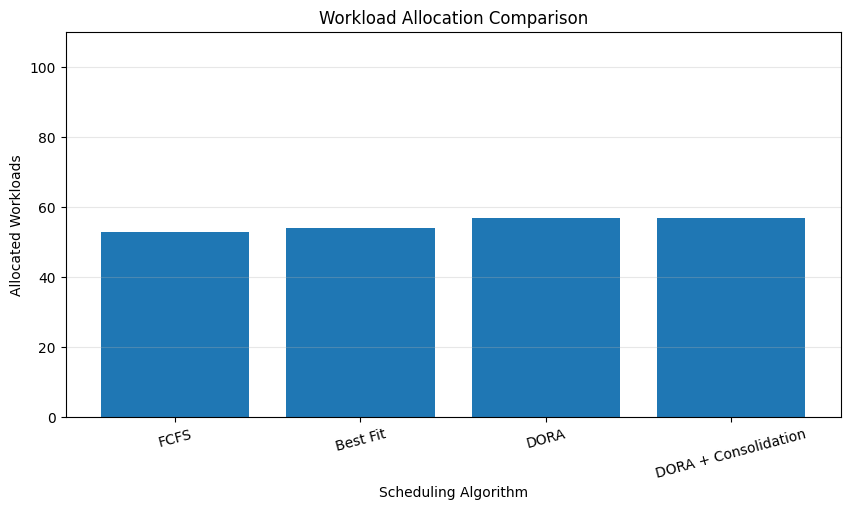

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    benchmark_df["Algorithm"],
    benchmark_df["Allocated"]
)

plt.title("Workload Allocation Comparison")
plt.xlabel("Scheduling Algorithm")
plt.ylabel("Allocated Workloads")
plt.ylim(0, TOTAL_WORKLOADS + 10)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()

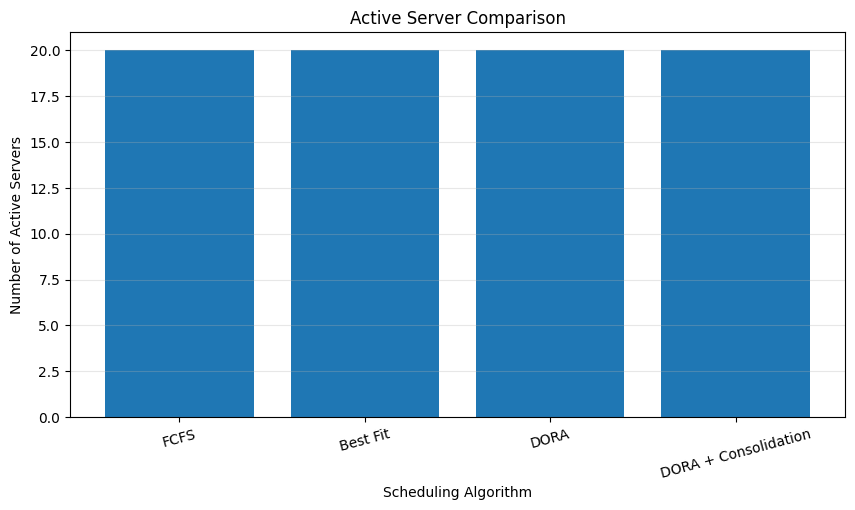

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    benchmark_df["Algorithm"],
    benchmark_df["Active Servers"]
)

plt.title("Active Server Comparison")
plt.xlabel("Scheduling Algorithm")
plt.ylabel("Number of Active Servers")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()

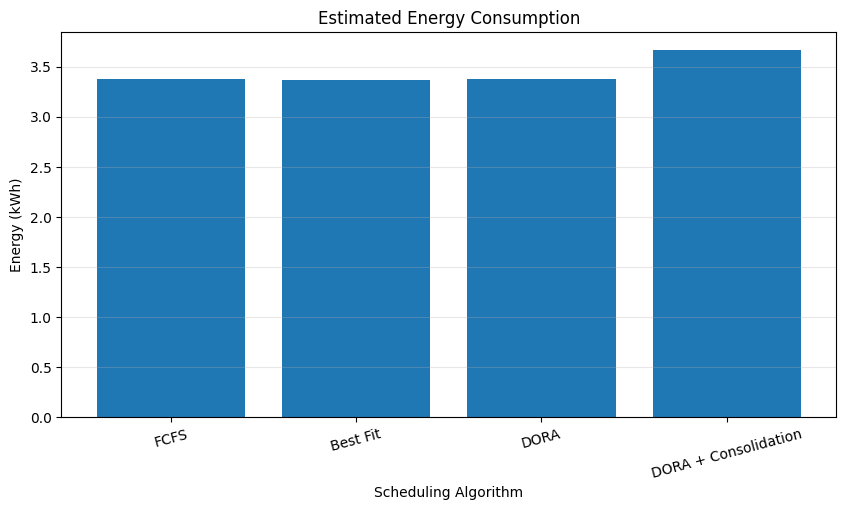

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    benchmark_df["Algorithm"],
    benchmark_df["Estimated Energy (kWh)"]
)

plt.title("Estimated Energy Consumption")
plt.xlabel("Scheduling Algorithm")
plt.ylabel("Energy (kWh)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()

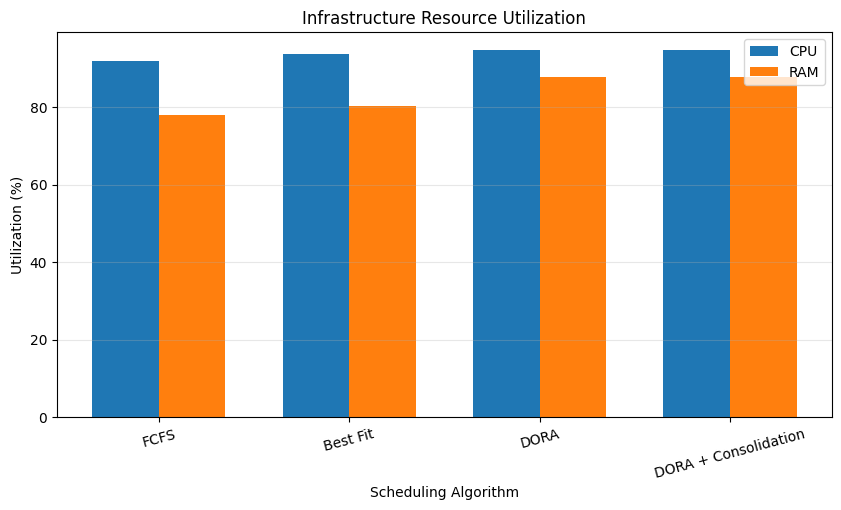

In [ ]:
x = np.arange(len(benchmark_df))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    benchmark_df["CPU Utilization (%)"],
    width,
    label="CPU"
)

plt.bar(
    x + width / 2,
    benchmark_df["RAM Utilization (%)"],
    width,
    label="RAM"
)

plt.title("Infrastructure Resource Utilization")
plt.xlabel("Scheduling Algorithm")
plt.ylabel("Utilization (%)")
plt.xticks(x, benchmark_df["Algorithm"], rotation=15)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
final_results = benchmark_df.copy()

final_results["Allocation Success (%)"] = (
    final_results["Allocation Success (%)"].round(2)
)

display(final_results)

print("\nNIMBUS DORA Evaluation Completed")
print("Total Workloads:", TOTAL_WORKLOADS)
print("Total Infrastructure Servers:", TOTAL_SERVERS)
print("Algorithms Evaluated:", len(final_results))

,Algorithm,Allocated,Rejected,Allocation Success (%),Active Servers,CPU Utilization (%),RAM Utilization (%),Estimated Energy (kWh)
0,FCFS,53,47,53.0,20,91.88,78.12,3.37404
1,Best Fit,54,46,54.0,20,93.75,80.31,3.36819
2,DORA,57,43,57.0,20,94.69,87.81,3.37518
3,DORA + Consolidation,57,43,57.0,20,94.69,87.81,3.66217



NIMBUS DORA Evaluation Completed
Total Workloads: 100
Total Infrastructure Servers: 20
Algorithms Evaluated: 4


12 — API Output for Frontend

In [ ]:
def build_nimbus_response():
    server_details = []
    for server in consolidated_dora_servers:
        energy = calculate_server_energy(server)
        server_details.append({
            "server_id": server.server_id,
            "status": "active" if server.workloads else "inactive",
            "cpu_capacity": server.cpu_capacity,
            "cpu_used": server.cpu_used,
            "cpu_utilization": round(server.cpu_utilization * 100, 2),
            "ram_capacity_gb": server.ram_capacity,
            "ram_used_gb": server.ram_used,
            "ram_utilization": round(server.ram_utilization * 100, 2),
            "workload_count": len(server.workloads),
            "estimated_power_w": energy["Estimated Power (W)"],
            "estimated_energy_kwh": energy["Energy (kWh)"],
        })

    allocation_details = []
    for item in dora_allocations:
        allocation_details.append({
            "workload_id": item["Workload ID"],
            "server_id": item["Server ID"],
            "cpu_required": item["CPU Required"],
            "ram_required_gb": item["RAM Required"],
            "execution_time_min": item["Execution Time"],
            "deadline_min": item["Deadline"],
            "priority": item["Priority"],
            "serial_runtime_min": item["Serial Runtime"],
            "dora_score": item["DORA Score"],
        })

    return {
        "project": "NIMBUS",
        "algorithm": "DORA",
        "simulation": {
            "total_servers": TOTAL_SERVERS,
            "total_workloads": TOTAL_WORKLOADS,
            "allocated_workloads": len(dora_allocations),
            "rejected_workloads": len(dora_rejected),
            "deadline_violations": len(dora_deadline_violations),
            "consolidation_failures": len(consolidation_failures),
        },
        "infrastructure": {
            "active_servers_before_consolidation": before_servers,
            "active_servers_after_consolidation": after_servers,
            "inactive_servers": TOTAL_SERVERS - after_servers,
            "estimated_energy_before_kwh": dora_energy,
            "estimated_energy_after_kwh": consolidated_energy,
            "energy_reduction_pct": round(
                (dora_energy - consolidated_energy) / dora_energy * 100, 2
            ) if dora_energy else 0.0,
        },
        "allocations": allocation_details,
        "servers": server_details,
        "benchmark": benchmark_df.to_dict(orient="records"),
        "simulation_assumptions": [
            "Static CPU and RAM allocation",
            "Workloads execute serially per server (sum of execution times)",
            "Unused servers are assumed to be switched off",
            "Deadlines are checked against serial runtime",
            "Energy values are estimates, not measured hardware consumption",
        ],
    }


nimbus_response = build_nimbus_response()
print("NIMBUS dashboard response created successfully!")
print("Top-level sections:", list(nimbus_response.keys()))

NIMBUS dashboard response created successfully!
Top-level sections: ['project', 'algorithm', 'simulation', 'infrastructure', 'allocations', 'servers', 'benchmark', 'simulation_assumptions']


In [ ]:
print(json.dumps(nimbus_response, indent=4)[:5000])

{
    "project": "NIMBUS",
    "algorithm": "DORA",
    "simulation": {
        "total_servers": 20,
        "total_workloads": 100,
        "allocated_workloads": 57,
        "rejected_workloads": 43,
        "consolidation_failures": 0
    },
    "infrastructure": {
        "active_servers": 20,
        "inactive_servers": 0,
        "estimated_energy_kwh": 3.66217
    },
    "allocations": [
        {
            "workload_id": "W029",
            "server_id": "S01",
            "cpu_required": 12,
            "ram_required_gb": 8,
            "execution_time_min": 40,
            "deadline_min": 11,
            "priority": 3,
            "dora_score": 0.525
        },
        {
            "workload_id": "W093",
            "server_id": "S01",
            "cpu_required": 4,
            "ram_required_gb": 4,
            "execution_time_min": 19,
            "deadline_min": 13,
            "priority": 3,
            "dora_score": 0.5812
        },
        {
            "workload_id":

In [ ]:
with open("nimbus_dashboard_data.json", "w") as file:
    json.dump(
        nimbus_response,
        file,
        indent=4,
        default=lambda x: x.item() if isinstance(x, np.generic) else str(x)
    )

print("JSON file exported successfully!")

JSON file exported successfully!


In [ ]:
from google.colab import files
files.download("nimbus_dashboard_data.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
with open("nimbus_dashboard_data.json", "r") as file:
    test_response = json.load(file)

print("JSON validation successful!")
print("Project:", test_response["project"])
print("Algorithm:", test_response["algorithm"])
print("Servers:", len(test_response["servers"]))
print("Allocations:", len(test_response["allocations"]))

JSON validation successful!
Project: NIMBUS
Algorithm: DORA
Servers: 20
Allocations: 57
